# Paired analysis

## Data load and processing

The section below uses an analysis ready data output that needs to be connected with home or work locations to link an user with a given zipcode of residence. 
If your dataset already contains a zipcode or home location lat/lon or it is already filtered to for an ROI, you might skip steps 2 through 5

In [2]:
# === Load packages
import pandas as pd
from pandas.api.types import CategoricalDtype

# === Step 1: Load full daily dataset
df = pd.read_parquet("/glade/work/jcelis/code/jcelis/2.mobility_code/Modular_approach/output_test/Daily_metrics_v2/output4_combined_distance_stops_full.parquet")
df["date"] = pd.to_datetime(df["date"])
df["uid"] = df["uid"].astype(str)

# === Step 2: Remove outliers over 500 miles (optional and only for distance based metrics)
df = df[df["distance_miles"] <= 500].copy()

# === Step 3: Load persistent users (45 days present)
uids_45dd = pd.read_csv("/glade/work/jcelis/mobility/data_products/Permanent_california_users_45dd.csv", header=None)[0].astype(str)

# === Step 4: Load home ZIP information
df_home = pd.read_parquet("/glade/derecho/scratch/ggantos/CAT/home_locations_tao_filtered/home_loc_by_row_group.parquet")
df_home = df_home.reset_index()
df_home["uid"] = df_home["uid"].astype(str)

# === Step 5: Merge and filter to persistent users
df_merged = df.merge(df_home, on="uid", how="left")
df_merged = df_merged[df_merged["uid"].isin(uids_45dd)].copy()


In [8]:
n_unique_uids = df_merged["uid"].nunique()
print(f"Unique matched devices: {n_unique_uids:,}")

Unique matched devices: 48,582


In [6]:
df_merged.head(5)

,uid,date,distance_miles,num_stops,duration_home,lat,lng,duration_work,lat_work,lng_work,zipcode,row_group
13747,0003232a3d22b394a8b589c18fa4dc753b16bd32595d0c...,2024-03-14,12.324113,4,17 days 04:05:47,34.082883,-117.956829,13 days 11:49:11,34.04169,-118.026807,91706,2.0
13748,0003232a3d22b394a8b589c18fa4dc753b16bd32595d0c...,2024-03-15,4.614999,2,17 days 04:05:47,34.082883,-117.956829,13 days 11:49:11,34.04169,-118.026807,91706,2.0
13749,0003232a3d22b394a8b589c18fa4dc753b16bd32595d0c...,2024-03-16,4.905899,3,17 days 04:05:47,34.082883,-117.956829,13 days 11:49:11,34.04169,-118.026807,91706,2.0
13750,0003232a3d22b394a8b589c18fa4dc753b16bd32595d0c...,2024-03-17,179.247654,7,17 days 04:05:47,34.082883,-117.956829,13 days 11:49:11,34.04169,-118.026807,91706,2.0
13751,0003232a3d22b394a8b589c18fa4dc753b16bd32595d0c...,2024-03-18,34.136066,3,17 days 04:05:47,34.082883,-117.956829,13 days 11:49:11,34.04169,-118.026807,91706,2.0


 For the list of zipcodes, a .yaml file with the information would be better

In [3]:
zipcodes_custom = [
    '90001', '90002', '90003', '90004', '90005', '90006', '90007', '90008', '90009', '90010',
    '90011', '90012', '90013', '90014', '90015', '90016', '90017', '90018', '90019', '90020',
    '90021', '90022', '90023', '90024', '90025', '90026', '90027', '90028', '90029', '90030',
    '90031', '90032', '90033', '90034', '90035', '90036', '90037', '90038', '90039', '90040',
    '90041', '90042', '90043', '90044', '90045', '90046', '90047', '90048', '90049', '90050',
    '90051', '90052', '90053', '90054', '90055', '90056', '90057', '90058', '90059', '90060',
    '90061', '90062', '90063', '90064', '90065', '90066', '90067', '90068', '90069', '90070',
    '90071', '90072', '90073', '90074', '90075', '90076', '90077', '90078', '90079', '90080',
    '90081', '90082', '90083', '90084', '90086', '90087', '90088', '90089', '90090', '90091',
    '90093', '90094', '90095', '90096', '90097', '90099', '90101', '90102', '90103', '90174',
    '90185', '90189', '90201', '90202', '90209', '90210', '90211', '90212', '90213', '90220',
    '90221', '90222', '90223', '90224', '90230', '90231', '90232', '90233', '90239', '90240',
    '90241', '90242', '90245', '90247', '90248', '90249', '90250', '90251', '90254', '90255',
    '90260', '90261', '90262', '90263', '90264', '90265', '90266', '90267', '90270', '90272',
    '90274', '90275', '90277', '90278', '90280', '90290', '90291', '90292', '90293', '90294',
    '90295', '90296', '90301', '90302', '90303', '90304', '90305', '90306', '90307', '90308',
    '90309', '90310', '90311', '90312', '90313', '90397', '90398', '90401', '90402', '90403',
    '90404', '90405', '90406', '90407', '90408', '90409', '90410', '90411', '90501', '90502',
    '90503', '90504', '90505', '90506', '90507', '90508', '90509', '90510', '90601', '90602',
    '90603', '90604', '90605', '90606', '90607', '90608', '90609', '90610', '90612', '90631',
    '90637', '90638', '90639', '90640', '90650', '90651', '90652', '90659', '90660', '90661',
    '90662', '90665', '90670', '90671', '90701', '90702', '90703', '90704', '90706', '90707',
    '90710', '90711', '90712', '90713', '90714', '90715', '90716', '90717', '90723', '90731',
    '90732', '90733', '90734', '90744', '90745', '90746', '90747', '90748', '90749', '90755',
    '90801', '90802', '90803', '90804', '90805', '90806', '90807', '90808', '90809', '90810',
    '90813', '90814', '90815', '90822', '90831', '90832', '90833', '90834', '90835', '90840',
    '90842', '90844', '90845', '90846', '90847', '90848', '90853', '90888', '90895', '90899',
    '91001', '91003', '91006', '91007', '91008', '91009', '91010', '91011', '91012', '91016',
    '91017', '91020', '91023', '91024', '91025', '91030', '91031', '91040', '91041', '91042',
    '91043', '91046', '91066', '91077', '91101', '91102', '91103', '91104', '91105', '91106',
    '91107', '91108', '91109', '91110', '91114', '91115', '91116', '91117', '91118', '91121',
    '91123', '91124', '91125', '91126', '91129', '91131', '91175', '91182', '91184', '91185',
    '91186', '91187', '91188', '91189', '91191', '91201', '91202', '91203', '91204', '91205',
    '91206', '91207', '91208', '91209', '91210', '91214', '91221', '91222', '91224', '91225',
    '91226', '91301', '91302', '91303', '91304', '91305', '91306', '91307', '91308', '91309',
    '91310', '91311', '91312', '91313', '91316', '91319', '91320', '91321', '91322', '91324',
    '91325', '91326', '91327', '91328', '91329', '91330', '91331', '91333', '91334', '91335',
    '91337', '91340', '91341', '91343', '91344', '91345', '91346', '91350', '91351', '91352',
    '91353', '91354', '91355', '91356', '91357', '91359', '91360', '91361', '91362', '91363',
    '91364', '91365', '91367', '91371', '91372', '91376', '91377', '91380', '91381', '91382',
    '91383', '91384', '91385', '91386', '91387', '91388', '91390', '91393', '91399', '91401',
    '91402', '91403', '91405', '91406', '91409', '91411', '91423', '91436', '91497', '91501',
    '91502', '91504', '91505', '91506', '91601', '91602', '91604', '91605', '91606', '91607',
    '91608', '91702', '91706', '91711', '91722', '91723', '91724', '91731', '91732', '91733',
    '91734', '91735', '91740', '91741', '91744', '91745', '91746', '91747', '91748', '91749',
    '91750', '91754', '91755', '91756', '91759', '91765', '91767', '91768', '91769', '91770',
    '91771', '91772', '91773', '91775', '91776', '91778', '91780', '91788', '91789', '91790',
    '91791', '91792', '91793', '91795', '91797', '91799', '91801', '91802', '91803', '91804',
    '91841', '91896', '91899', '92397', '93001', '93002', '93003', '93004', '93005', '93006',
    '93007', '93009', '93010', '93011', '93012', '93013', '93014', '93015', '93016', '93020',
    '93021', '93022', '93023', '93024', '93030', '93031', '93032', '93033', '93034', '93035',
    '93036', '93040', '93041', '93042', '93043', '93044', '93060', '93061', '93062', '93063',
    '93064', '93065', '93066', '93067', '93093', '93094', '93099', '93101', '93102', '93103',
    '93105', '93106', '93107', '93108', '93109', '93110', '93111', '93116', '93117', '93118',
    '93120', '93121', '93130', '93140', '93150', '93160', '93190', '93199', '93225', '93243',
    '93252', '93254', '93427', '93429', '93434', '93436', '93437', '93438', '93440', '93441',
    '93454', '93455', '93456', '93457', '93458', '93460', '93463', '93464'
]

In [4]:
# === Step 6: Filter to ROI ZIP codes
df_merged["zipcode"] = df_merged["zipcode"].astype(str)
df_roi = df_merged[df_merged["zipcode"].isin(zipcodes_custom)].copy()

# === Step 7: Add AR flag and weekday
df_roi["is_ar"] = df_roi["date"].between("2024-03-27", "2024-04-01")
df_roi["weekday"] = df_roi["date"].dt.day_name()

# === Step 8: Paired analysis – average per user
paired_summary = df_roi.groupby(["uid", "is_ar"]).agg(
    avg_distance=("distance_miles", "mean"),
    avg_trips=("num_stops", "mean"),
).reset_index()

# === Step 9: Pivot for paired difference
paired_pivot = paired_summary.pivot(index="uid", columns="is_ar", values=["avg_distance", "avg_trips"])
paired_pivot.columns = ["non_ar_distance", "ar_distance", "non_ar_trips", "ar_trips"]
paired_pivot = paired_pivot.dropna()

# === Step 10: Compute deltas
paired_pivot["delta_distance"] = paired_pivot["ar_distance"] - paired_pivot["non_ar_distance"]
paired_pivot["delta_trips"] = paired_pivot["ar_trips"] - paired_pivot["non_ar_trips"]


In [26]:
# Print basic stats
print(f" Number of devices with paired data: {paired_pivot.shape[0]:,}")
print("\n Summary statistics (per-user deltas):")
print(paired_pivot[["delta_distance", "delta_trips"]].describe())


 Number of devices with paired data: 10,845

 Summary statistics (per-user deltas):
       delta_distance   delta_trips
count    10845.000000  10845.000000
mean        -3.681235     -0.294345
std         31.263249      1.037375
min       -269.143464    -10.333333
25%        -15.653676     -0.914414
50%         -3.518213     -0.294872
75%          5.277401      0.316667
max        316.495594      5.983740


In [9]:
n_unique_uids = df_roi["uid"].nunique()
print(f"Unique matched devices: {n_unique_uids:,}")

Unique matched devices: 10,849


In [11]:
df_roi.to_parquet(
    "/glade/work/jcelis/mobility/data_products/processed_paired_dataset.parquet",
    index=False
)

In [25]:
from scipy.stats import ttest_rel

print("Paired t-test for Distance:")
print(ttest_rel(paired_pivot["ar_distance"], paired_pivot["non_ar_distance"]))

print("\nPaired t-test for Trips:")
print(ttest_rel(paired_pivot["ar_trips"], paired_pivot["non_ar_trips"]))

print("\nDelta Distance Summary:")
print(paired_pivot["delta_distance"].describe())

print("\nDelta Trips Summary:")
print(paired_pivot["delta_trips"].describe())



Paired t-test for Distance:
TtestResult(statistic=-12.262364896869597, pvalue=2.43409128826338e-34, df=10844)

Paired t-test for Trips:
TtestResult(statistic=-29.54847303055551, pvalue=1.2588924742732347e-184, df=10844)

Delta Distance Summary:
count    10845.000000
mean        -3.681235
std         31.263249
min       -269.143464
25%        -15.653676
50%         -3.518213
75%          5.277401
max        316.495594
Name: delta_distance, dtype: float64

Delta Trips Summary:
count    10845.000000
mean        -0.294345
std          1.037375
min        -10.333333
25%         -0.914414
50%         -0.294872
75%          0.316667
max          5.983740
Name: delta_trips, dtype: float64


## Graphics and Visualization

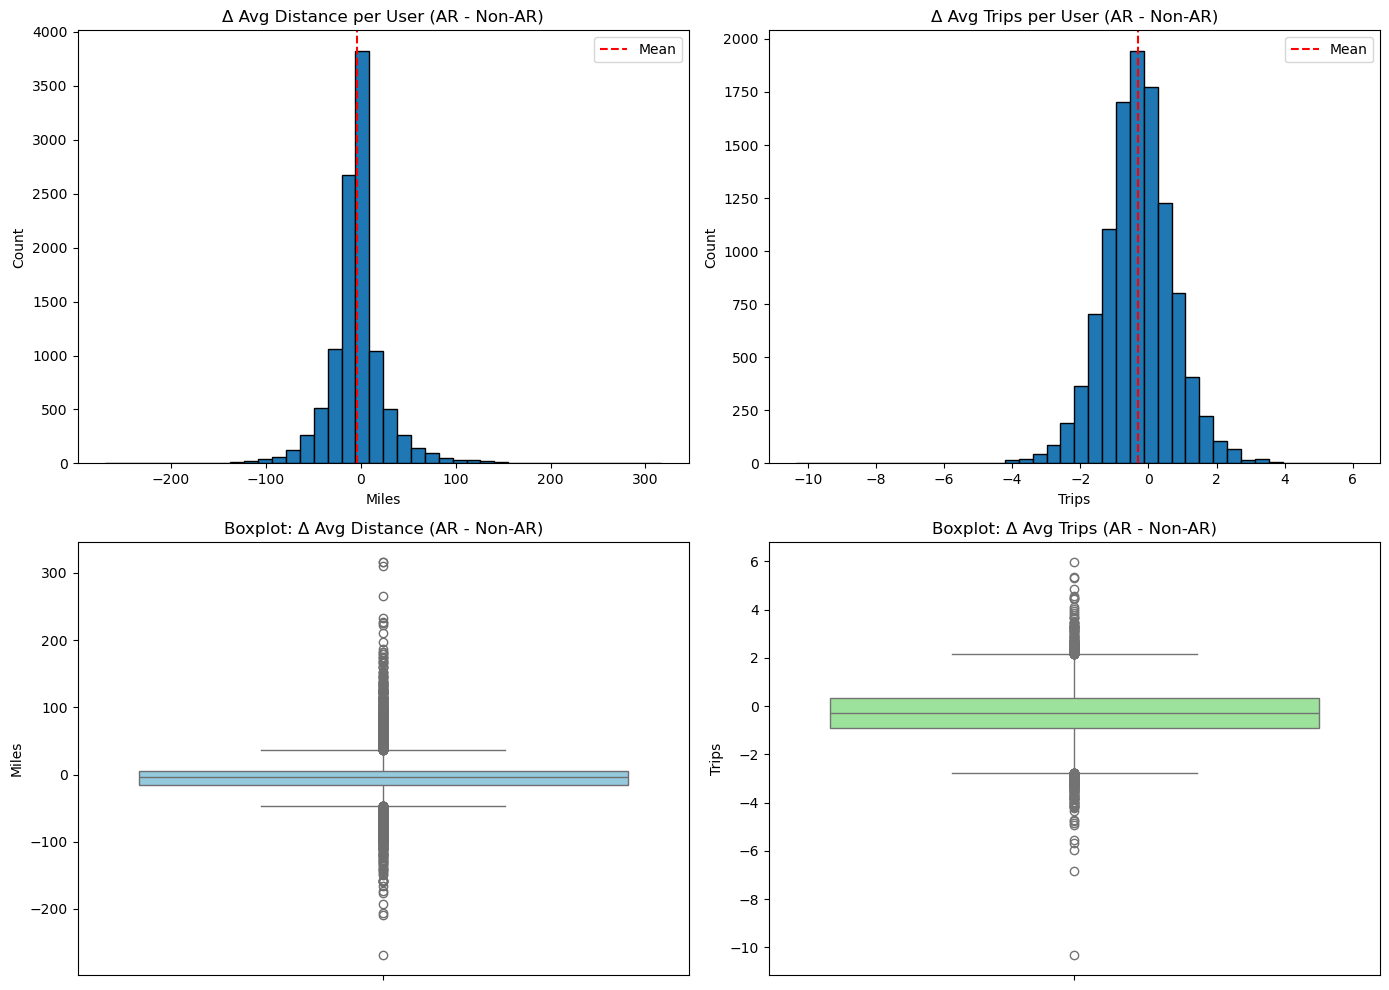

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Basic Visualizations
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Histogram: Delta Distance
axs[0, 0].hist(paired_pivot["delta_distance"], bins=40, edgecolor='black')
axs[0, 0].axvline(paired_pivot["delta_distance"].mean(), color='red', linestyle='--', label='Mean')
axs[0, 0].set_title("Δ Avg Distance per User (AR - Non-AR)")
axs[0, 0].set_xlabel("Miles")
axs[0, 0].set_ylabel("Count")
axs[0, 0].legend()

# Histogram: Delta Trips
axs[0, 1].hist(paired_pivot["delta_trips"], bins=40, edgecolor='black')
axs[0, 1].axvline(paired_pivot["delta_trips"].mean(), color='red', linestyle='--', label='Mean')
axs[0, 1].set_title("Δ Avg Trips per User (AR - Non-AR)")
axs[0, 1].set_xlabel("Trips")
axs[0, 1].set_ylabel("Count")
axs[0, 1].legend()

# Boxplot: Delta Distance
sns.boxplot(y=paired_pivot["delta_distance"], ax=axs[1, 0], color="skyblue")
axs[1, 0].set_title("Boxplot: Δ Avg Distance (AR - Non-AR)")
axs[1, 0].set_ylabel("Miles")

# Boxplot: Delta Trips
sns.boxplot(y=paired_pivot["delta_trips"], ax=axs[1, 1], color="lightgreen")
axs[1, 1].set_title("Boxplot: Δ Avg Trips (AR - Non-AR)")
axs[1, 1].set_ylabel("Trips")

plt.tight_layout()
plt.show()

In [30]:
import pandas as pd
import geopandas as gpd
import folium
from branca.colormap import LinearColormap
import json

# Step 1: Count unique users per ZIP code
zip_counts = df_roi.groupby("zipcode")["uid"].nunique().reset_index()
zip_counts.columns = ["zipcode", "num_users"]
zip_counts["zipcode"] = zip_counts["zipcode"].astype(str)

# Step 2: Load ZIP code GeoJSON
zip_codes_url = "https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/ca_california_zip_codes_geo.min.json"
zip_gdf = gpd.read_file(zip_codes_url)
zip_gdf["ZIP"] = zip_gdf["ZCTA5CE10"].astype(str)

# Step 3: Merge counts with GeoJSON
gdf_merged = zip_gdf.merge(zip_counts, left_on="ZIP", right_on="zipcode", how="left")
gdf_merged["num_users"] = gdf_merged["num_users"].fillna(0)
gdf_merged = gdf_merged.to_crs("EPSG:4326")

# Step 4: Split into visible and transparent layers
gdf_with_users = gdf_merged[gdf_merged["num_users"] > 0]
gdf_no_users = gdf_merged[gdf_merged["num_users"] == 0]

# Step 5: Create color scale based on user count
vmax = gdf_with_users["num_users"].max()
colormap = LinearColormap(
    colors=["#ffffcc", "#fd8d3c", "#800026"],  # light yellow to dark red
    vmin=0,
    vmax=vmax,
    caption="Number of Unique Devices"
)

# Step 6: Initialize zoomed-in map around LA/Southern California
m = folium.Map(location=[34.05, -118.25], zoom_start=9, tiles="CartoDB positron")

# Step 7: Add ZIPs with user data as choropleth
folium.GeoJson(
    gdf_with_users,
    style_function=lambda feature: {
        "fillColor": colormap(feature["properties"]["num_users"]),
        "color": "white",
        "weight": 0.4,
        "fillOpacity": 0.7,
    },
    tooltip=folium.GeoJsonTooltip(fields=["ZIP", "num_users"], aliases=["ZIP", "Unique Devices"]),
).add_to(m)

# Step 8: Add ZIP outlines for ZIPs with no users
folium.GeoJson(
    gdf_no_users,
    style_function=lambda x: {
        "fillOpacity": 0,
        "color": "lightgray",
        "weight": 0.4,
    }
).add_to(m)

# Step 9: Add colormap legend
colormap.add_to(m)

# Optional: Add key city markers for orientation
folium.Marker([34.0522, -118.2437], popup="Los Angeles", icon=folium.Icon(color="blue")).add_to(m)
folium.Marker([34.4208, -119.6982], popup="Santa Barbara", icon=folium.Icon(color="green")).add_to(m)
folium.Marker([34.2746, -119.2290], popup="Ventura", icon=folium.Icon(color="purple")).add_to(m)

# Step 10: Save or display
#m.save("interactive_zip_map_socal.html")

# Uncomment this following line to create the map
#m


In [15]:
df_roi_base= df_roi

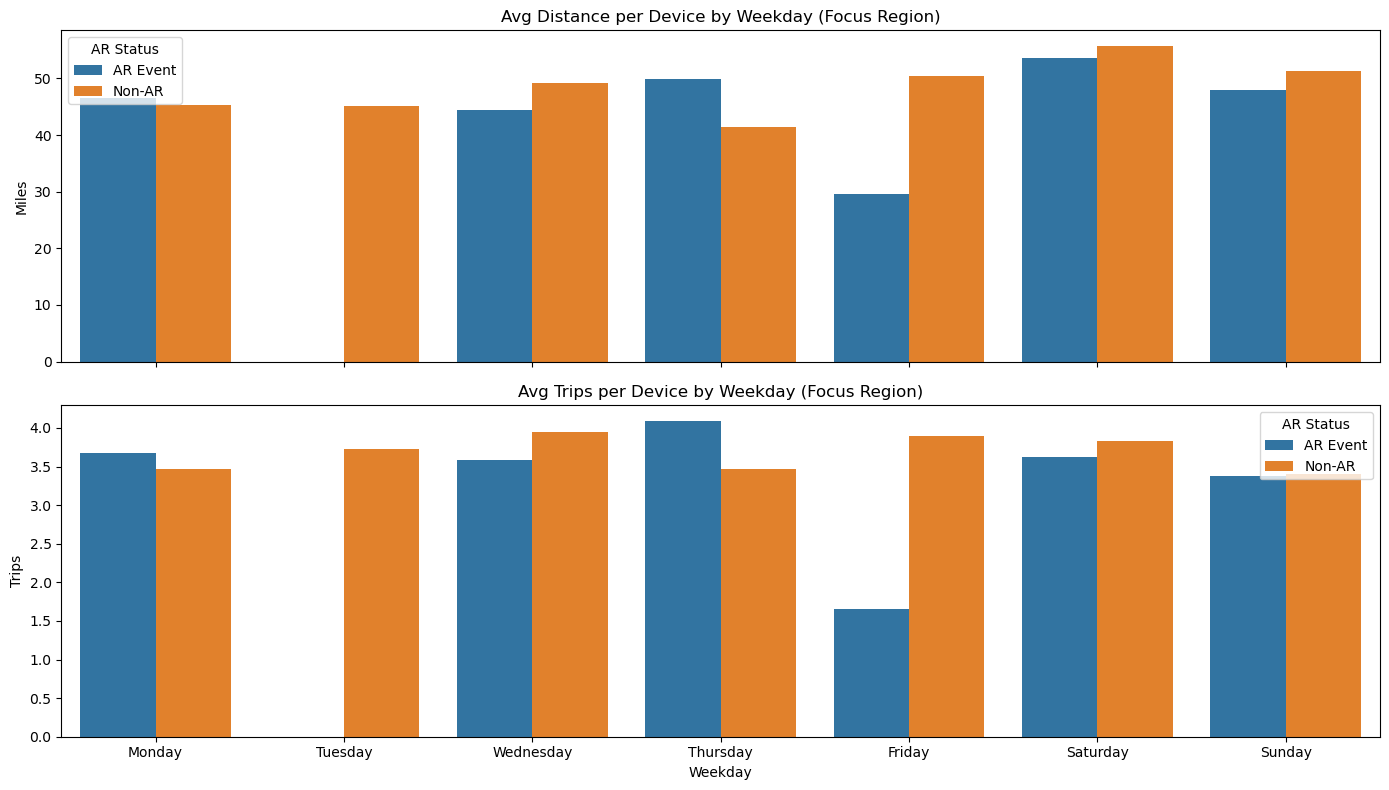

In [18]:
import folium
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import CategoricalDtype

# --- Metric comparison (AR vs. Non-AR) ---
df_roi["date"] = pd.to_datetime(df_roi["date"])
df_roi["weekday"] = df_roi["date"].dt.day_name()
df_roi["is_ar"] = df_roi["date"].between("2024-03-27", "2024-04-01")
df_roi["AR Status"] = df_roi["is_ar"].map({True: "AR Event", False: "Non-AR"})

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_cat = CategoricalDtype(categories=weekday_order, ordered=True)
df_roi["weekday"] = df_roi["weekday"].astype(weekday_cat)

agg_df = df_roi.groupby(["date", "zipcode"]).agg(
    total_distance=("distance_miles", "sum"),
    total_trips=("num_stops", "sum"),
    num_devices=("uid", "nunique")
).reset_index()

agg_df["avg_distance_per_device"] = agg_df["total_distance"] / agg_df["num_devices"]
agg_df["avg_trips_per_device"] = agg_df["total_trips"] / agg_df["num_devices"]
agg_df["weekday"] = agg_df["date"].dt.day_name()
agg_df["is_ar"] = agg_df["date"].between("2024-03-27", "2024-04-01")
agg_df["AR Status"] = agg_df["is_ar"].map({True: "AR Event", False: "Non-AR"})
agg_df["weekday"] = agg_df["weekday"].astype(weekday_cat)

weekday_comp = agg_df.groupby(["weekday", "AR Status"], observed=True).agg(
    avg_distance_per_device=("avg_distance_per_device", "mean"),
    avg_trips_per_device=("avg_trips_per_device", "mean")
).reset_index().sort_values("weekday")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
sns.barplot(data=weekday_comp, x="weekday", y="avg_distance_per_device", hue="AR Status", ax=axes[0])
axes[0].set_title("Avg Distance per Device by Weekday (Focus Region)")
axes[0].set_ylabel("Miles")

sns.barplot(data=weekday_comp, x="weekday", y="avg_trips_per_device", hue="AR Status", ax=axes[1])
axes[1].set_title("Avg Trips per Device by Weekday (Focus Region)")
axes[1].set_ylabel("Trips")
axes[1].set_xlabel("Weekday")

plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

# Step 1: Ensure AR labels and datetime
df_roi["date"] = pd.to_datetime(df_roi["date"])
df_roi["is_ar"] = df_roi["date"].between("2024-03-27", "2024-04-01")
df_roi["AR Status"] = df_roi["is_ar"].map({True: "AR Event", False: "Non-AR"})

# Step 2: Per-user daily average within each ZIP and AR status
user_zip_stats = df_roi.groupby(["uid", "zipcode", "AR Status"]).agg(
    avg_distance=("distance_miles", "mean"),
    avg_trips=("num_stops", "mean")
).reset_index()

# Step 3: Pivot so AR and Non-AR are side-by-side per user
pivoted = user_zip_stats.pivot(index=["uid", "zipcode"], columns="AR Status", values=["avg_distance", "avg_trips"])
pivoted.columns = ['avg_dist_ar', 'avg_dist_nonar', 'avg_trips_ar', 'avg_trips_nonar']
pivoted = pivoted.dropna()

# Step 4: Calculate per-user deltas
pivoted["delta_distance"] = pivoted["avg_dist_ar"] - pivoted["avg_dist_nonar"]
pivoted["delta_trips"] = pivoted["avg_trips_ar"] - pivoted["avg_trips_nonar"]
pivoted = pivoted.reset_index()

# Step 5: Aggregate per ZIP
zip_summary = pivoted.groupby("zipcode").agg(
    avg_delta_distance=("delta_distance", "mean"),
    avg_delta_trips=("delta_trips", "mean"),
    num_users=("uid", "nunique")
).reset_index()

# Show preview
print(zip_summary.head())


  zipcode  avg_delta_distance  avg_delta_trips  num_users
0   90001           -4.376599        -0.348455         47
1   90002            2.715509        -0.180138         55
2   90003           -7.026680        -0.452741         39
3   90004           -4.967696        -0.316498         60
4   90005           -5.244598        -0.575537         63


In [31]:
import geopandas as gpd
import folium
from branca.colormap import LinearColormap
import json

# Step 6: Load CA ZIP shapefile
zip_codes_url = "https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/ca_california_zip_codes_geo.min.json"
zip_gdf = gpd.read_file(zip_codes_url)
zip_gdf["ZIP"] = zip_gdf["ZCTA5CE10"].astype(str)

# Step 7: Merge with zip_summary
zip_summary["zipcode"] = zip_summary["zipcode"].astype(str)
gdf_map = zip_gdf.merge(zip_summary, left_on="ZIP", right_on="zipcode", how="left")
gdf_map = gdf_map.to_crs("EPSG:4326")
gdf_map["avg_delta_distance"] = gdf_map["avg_delta_distance"].fillna(0)

# Step 8: Create diverging colormap
vmax = gdf_map["avg_delta_distance"].max()
vmin = gdf_map["avg_delta_distance"].min()
vmax_abs = max(abs(vmin), abs(vmax))

colormap = LinearColormap(
    colors=["red", "white", "green"],  # Blue = decreased, Red = increased
    vmin=-vmax_abs, vmax=vmax_abs,
    caption="Δ Avg Distance (AR - Non-AR)"
)

# Step 9: Initialize map
m = folium.Map(location=[34.05, -118.25], zoom_start=9, tiles="CartoDB positron")

# Step 10: Plot ZIPs with change
folium.GeoJson(
    gdf_map,
    style_function=lambda feature: {
        "fillColor": colormap(feature["properties"]["avg_delta_distance"]),
        "color": "gray",
        "weight": 0.4,
        "fillOpacity": 0.7 if feature["properties"]["avg_delta_distance"] != 0 else 0,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["ZIP", "avg_delta_distance", "num_users"],
        aliases=["ZIP", "Δ Miles", "# Users"],
        localize=True
    )
).add_to(m)

colormap.add_to(m)
# Uncomment this following line to create the map
#m


In [ ]:
# DO IT ALL IN ONE FUNCTION 

# import folium
# import geopandas as gpd
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns
# from pandas.api.types import CategoricalDtype

# # --- STEP 1: Map home + work locations ---
# df_plot_focus = df_roi.drop_duplicates("uid").dropna(subset=["lat", "lng", "lat_work", "lng_work"])
# gdf_home_focus = gpd.GeoDataFrame(df_plot_focus, geometry=gpd.points_from_xy(df_plot_focus.lng, df_plot_focus.lat), crs="EPSG:4326")
# gdf_work_focus = gpd.GeoDataFrame(df_plot_focus, geometry=gpd.points_from_xy(df_plot_focus.lng_work, df_plot_focus.lat_work), crs="EPSG:4326")

# center_lat, center_lon = gdf_home_focus["lat"].mean(), gdf_home_focus["lng"].mean()
# m_focus = folium.Map(location=[center_lat, center_lon], zoom_start=10, tiles="CartoDB Positron")

# for _, row in gdf_home_focus.iterrows():
#     folium.CircleMarker([row.geometry.y, row.geometry.x], radius=4, color='blue', fill=True, fill_opacity=0.6).add_to(m_focus)

# for _, row in gdf_work_focus.iterrows():
#     folium.CircleMarker([row.lat_work, row.lng_work], radius=4, color='green', fill=True, fill_opacity=0.6).add_to(m_focus)

# legend_html = """
# <div style="position: fixed; bottom: 40px; left: 40px; width: 160px; height: 90px;
#              background-color: white; border:2px solid grey; z-index:9999;
#              font-size:14px; padding: 10px;">
# <b>Legend</b><br>
# <span style="color:blue;">●</span> Home Location<br>
# <span style="color:green;">●</span> Work Location
# </div>
# """
# m_focus.get_root().html.add_child(folium.Element(legend_html))


# # --- STEP 2: ZIP count choropleth ---
# zip_counts_focus = df_roi.groupby("zipcode")["uid"].nunique().reset_index()
# zip_counts_focus.columns = ["zipcode", "num_users"]
# zip_counts_focus["zipcode"] = zip_counts_focus["zipcode"].astype(str)

# zip_codes_url = "https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/ca_california_zip_codes_geo.min.json"
# zip_codes = gpd.read_file(zip_codes_url)
# zip_codes["ZIP"] = zip_codes["ZCTA5CE10"].astype(str)

# gdf_merged_focus = zip_codes.merge(zip_counts_focus, left_on="ZIP", right_on="zipcode", how="left")
# gdf_merged_focus["num_users"] = gdf_merged_focus["num_users"].fillna(0)

# california_url = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/master/public/data/california-counties.geojson"
# california_shape = gpd.read_file(california_url)

# fig, ax = plt.subplots(figsize=(12, 12))
# gdf_merged_focus[gdf_merged_focus["num_users"] > 0].plot(
#     column="num_users", cmap="YlOrRd", linewidth=0.5, edgecolor="gray", legend=True, ax=ax,
#     legend_kwds={"label": "Number of Unique Devices", "shrink": 0.6}
# )
# gdf_merged_focus[gdf_merged_focus["num_users"] == 0].plot(ax=ax, facecolor="none", edgecolor="lightgray", linewidth=0.3)
# california_shape.boundary.plot(ax=ax, color="black", linewidth=0.6)
# ax.set_title("Tracked Devices by ZIP Code – Focus Region", fontsize=16)
# ax.axis("off")
# plt.tight_layout()
# plt.show()


# # --- STEP 3: Metric comparison (AR vs. Non-AR) ---
# df_roi["date"] = pd.to_datetime(df_roi["date"])
# df_roi["weekday"] = df_roi["date"].dt.day_name()
# df_roi["is_ar"] = df_roi["date"].between("2024-03-27", "2024-04-01")
# df_roi["AR Status"] = df_roi["is_ar"].map({True: "AR Event", False: "Non-AR"})

# weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
# weekday_cat = CategoricalDtype(categories=weekday_order, ordered=True)
# df_roi["weekday"] = df_roi["weekday"].astype(weekday_cat)

# agg_df = df_roi.groupby(["date", "zipcode"]).agg(
#     total_distance=("distance_miles", "sum"),
#     total_trips=("num_stops", "sum"),
#     num_devices=("uid", "nunique")
# ).reset_index()

# agg_df["avg_distance_per_device"] = agg_df["total_distance"] / agg_df["num_devices"]
# agg_df["avg_trips_per_device"] = agg_df["total_trips"] / agg_df["num_devices"]
# agg_df["weekday"] = agg_df["date"].dt.day_name()
# agg_df["is_ar"] = agg_df["date"].between("2024-03-27", "2024-04-01")
# agg_df["AR Status"] = agg_df["is_ar"].map({True: "AR Event", False: "Non-AR"})
# agg_df["weekday"] = agg_df["weekday"].astype(weekday_cat)

# weekday_comp = agg_df.groupby(["weekday", "AR Status"], observed=True).agg(
#     avg_distance_per_device=("avg_distance_per_device", "mean"),
#     avg_trips_per_device=("avg_trips_per_device", "mean")
# ).reset_index().sort_values("weekday")

# fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
# sns.barplot(data=weekday_comp, x="weekday", y="avg_distance_per_device", hue="AR Status", ax=axes[0])
# axes[0].set_title("Avg Distance per Device by Weekday (Focus Region)")
# axes[0].set_ylabel("Miles")

# sns.barplot(data=weekday_comp, x="weekday", y="avg_trips_per_device", hue="AR Status", ax=axes[1])
# axes[1].set_title("Avg Trips per Device by Weekday (Focus Region)")
# axes[1].set_ylabel("Trips")
# axes[1].set_xlabel("Weekday")

# plt.tight_layout()
# plt.show()

# # Return the folium map
# m_focus